<a href="https://colab.research.google.com/github/AHMADAMJAD0/NLP_with_Olga/blob/main/spam_logreg_colab_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SMS Spam Classification: Logistic Regression from Scratch

Binary classifier (spam = 1, ham = 0) using only NumPy. Notation and code structure follow what we did in class:

- `X` is **n × m** (features × samples), the weights `theta` are **n × 1**, `y` is **m × 1**
- `z = Xᵀθ`, `ŷ = σ(z)`
- cost: `J = -(1/m) Σ [y log ŷ + (1-y) log(1-ŷ)]`
- gradient: `d_theta = (1/m) X (ŷ − y)`, update `theta ← theta − α·d_theta`
- prediction: spam (1) if `ŷ ≥ threshold`, with threshold = 0.5

**Before running:** upload `SMS_Spam_Corpus_big.txt` when the next cell asks (or put it in the Colab file panel).

In [1]:
import os, re
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

FILE = "SMS_Spam_Corpus_big.txt"
if not os.path.exists(FILE):
    from google.colab import files
    uploaded = files.upload()          # choose SMS_Spam_Corpus_big.txt
    FILE = list(uploaded.keys())[0]
print("Using file:", FILE)

Saving SMS_Spam_Corpus_big.txt to SMS_Spam_Corpus_big.txt
Using file: SMS_Spam_Corpus_big.txt


## 1. Compile texts and labels
The file is Latin-1 (it contains `£`), and each line is `message,label`. Exact duplicate messages are dropped so the same text can't land in both train and test.

In [2]:
texts, labels, seen = [], [], set()
with open(FILE, encoding="latin-1") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        msg, _, lab = line.rpartition(",")
        msg = msg.strip().strip('"')
        if msg in seen:
            continue
        seen.add(msg)
        texts.append(msg)
        labels.append(1 if lab.strip().lower() == "spam" else 0)

y_all = np.array(labels)
print(f"{len(texts)} unique messages, {y_all.mean():.1%} spam")
for t, l in list(zip(texts, labels))[:3]:
    print(l, "|", t[:80])

1272 unique messages, 23.4% spam
1 | Urgent! call 09061749602 from Landline. Your complimentary 4* Tenerife Holiday o
1 | +449071512431 URGENT! This is the 2nd attempt to contact U!U have WON £1250 CALL
1 | FREE for 1st week! No1 Nokia tone 4 ur mob every week just txt NOKIA to 8007 Get


## 2. Preprocess
Lowercase, replace URLs / currency symbols / long numbers / other numbers with tokens (these are strong spam cues), strip punctuation, drop stopwords.

In [3]:
STOP = set("""a an the and or but if of to in on at for with by from as is are was were be been
i me my we our you your he she it its they them their this that these those am do does did
have has had not no so too very can will just than then there here what which who whom""".split())

def preprocess(text):
    t = text.lower()
    t = re.sub(r"(https?://\S+|www\.\S+)", " urltoken ", t)
    t = re.sub(r"[£$€]", " currency ", t)
    t = re.sub(r"\d{5,}", " longnumber ", t)      # phone numbers, short codes
    t = re.sub(r"\d+", " number ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return [w for w in t.split() if len(w) > 1 and w not in STOP]

tokens = [preprocess(t) for t in texts]
print(texts[0]); print(tokens[0])

Urgent! call 09061749602 from Landline. Your complimentary 4* Tenerife Holiday or £10,000 cash await collection SAE T&Cs BOX 528 HP20 1YF 150ppm 18+
['urgent', 'call', 'longnumber', 'landline', 'complimentary', 'number', 'tenerife', 'holiday', 'currency', 'number', 'number', 'cash', 'await', 'collection', 'sae', 'cs', 'box', 'number', 'hp', 'number', 'number', 'yf', 'number', 'ppm', 'number']


## 3. Random stratified split: train / validation / test (70 / 15 / 15)
Stratified so each split keeps the ~23% spam ratio.

In [4]:
rng = np.random.default_rng(42)
parts = {"tr": [], "va": [], "te": []}
for lab in (0, 1):
    idx = np.where(y_all == lab)[0]
    rng.shuffle(idx)
    a, b = int(0.70 * len(idx)), int(0.85 * len(idx))
    parts["tr"].append(idx[:a]); parts["va"].append(idx[a:b]); parts["te"].append(idx[b:])
tr, va, te = (rng.permutation(np.concatenate(parts[k])) for k in ("tr", "va", "te"))
print(len(tr), len(va), len(te))

889 191 192


## 4. Vectorize
Binary bag-of-words. The vocabulary comes from the **training split only** (words in at least 2 training messages), so no information leaks from validation/test. Row 0 of `X` is the bias (all ones).

In [5]:
doc_freq = Counter(w for i in tr for w in set(tokens[i]))
vocab = sorted(w for w, c in doc_freq.items() if c >= 2)
col = {w: j + 1 for j, w in enumerate(vocab)}

def vectorize(ids):
    X = np.zeros((len(vocab) + 1, len(ids)))     # n x m
    X[0, :] = 1.0
    for j, i in enumerate(ids):
        for w in set(tokens[i]):
            r = col.get(w)
            if r:
                X[r, j] = 1.0
    return X

X_train, X_val, X_test = vectorize(tr), vectorize(va), vectorize(te)
y_train, y_val, y_test = (y_all[i].reshape(-1, 1) for i in (tr, va, te))   # (m, 1)
print("vocab size:", len(vocab))
print("X_train", X_train.shape, "X_val", X_val.shape, "X_test", X_test.shape)

vocab size: 1015
X_train (1016, 889) X_val (1016, 191) X_test (1016, 192)


## 5. Model, in the style used in class
Shapes: `X` is (n, m), `theta` is (n, 1), `y` and `y_pred` are (m, 1).
`y_pred = σ(Xᵀ·theta)`, cost = `(-1/m) Σ [y log ŷ + (1-y) log(1-ŷ)]`, `d_theta = (1/m) X (ŷ − y)`, `theta ← theta − α·d_theta`.

In [6]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def compute_cost(y, y_pred):
    m = y.shape[0]
    y_pred = np.clip(y_pred, 1e-12, 1 - 1e-12)      # avoid log(0)
    a = np.multiply(y, np.log(y_pred))
    b = np.multiply(1 - y, np.log(1 - y_pred))
    return (-1 / m) * np.sum(a + b)

def train(X, y, alpha, num_iter, verbose=False):
    n, m = X.shape
    theta = np.zeros((n, 1))
    costs = []
    for i in range(num_iter):
        z = np.dot(X.T, theta)                      # (m, 1)
        y_pred = sigmoid(z)
        assert y.shape == y_pred.shape

        cost = compute_cost(y, y_pred)
        costs.append(cost)

        if verbose and i % 50 == 0:                 # print every 50th iteration
            print('Cost in iteration', i, 'is', cost)

        d_theta = (1 / m) * np.dot((y_pred - y).T, X.T)   # (1, n)
        d_theta = d_theta.T                                # (n, 1)
        theta = theta - alpha * d_theta
    return theta, costs

def predict(theta, X, threshold=0.5):
    return (sigmoid(np.dot(X.T, theta)) >= threshold).astype(int)   # (m, 1)

def metrics(y, y_hat):
    y, y_hat = y.ravel(), y_hat.ravel()
    TP = int(((y_hat == 1) & (y == 1)).sum()); TN = int(((y_hat == 0) & (y == 0)).sum())
    FP = int(((y_hat == 1) & (y == 0)).sum()); FN = int(((y_hat == 0) & (y == 1)).sum())
    acc  = (TP + TN) / (TP + TN + FP + FN)
    prec = TP / max(TP + FP, 1)
    rec  = TP / max(TP + FN, 1)
    f1   = 2 * prec * rec / max(prec + rec, 1e-12)
    return dict(TP=TP, FN=FN, FP=FP, TN=TN, acc=acc, prec=prec, rec=rec, f1=f1)

### Gradient check
Compare the analytic gradient with a numerical one on a few coordinates. A tiny difference means `d_theta` is correct.

In [7]:
theta0 = np.random.default_rng(1).normal(0, 0.1, (X_train.shape[0], 1))
m_tr = X_train.shape[1]
analytic = (1 / m_tr) * np.dot(X_train, sigmoid(np.dot(X_train.T, theta0)) - y_train)   # (n, 1)

eps = 1e-6
for k in np.random.default_rng(0).choice(theta0.shape[0], 5, replace=False):
    e = np.zeros_like(theta0); e[k] = eps
    num = (compute_cost(y_train, sigmoid(np.dot(X_train.T, theta0 + e))) -
           compute_cost(y_train, sigmoid(np.dot(X_train.T, theta0 - e)))) / (2 * eps)
    print(f"theta[{k}]  analytic={analytic[k, 0]: .3e}  numerical={num: .3e}")

theta[645]  analytic=-1.823e-03  numerical=-1.823e-03
theta[518]  analytic=-4.062e-03  numerical=-4.062e-03
theta[273]  analytic= 1.472e-03  numerical= 1.472e-03
theta[312]  analytic= 1.219e-03  numerical= 1.219e-03
theta[860]  analytic= 1.824e-03  numerical= 1.824e-03


## 6. Choose the learning rate α on the validation set
The test set is not touched here.

In [8]:
NUM_ITER = 2000
best = None
for alpha in (0.05, 0.1, 0.5, 1.0, 2.0):
    theta, costs = train(X_train, y_train, alpha, NUM_ITER)
    m = metrics(y_val, predict(theta, X_val))
    val_cost = compute_cost(y_val, sigmoid(np.dot(X_val.T, theta)))
    print(f"alpha={alpha:<4} train cost={costs[-1]:.4f}  val cost={val_cost:.4f}  "
          f"val acc={m['acc']:.3f}  prec={m['prec']:.3f}  rec={m['rec']:.3f}  F1={m['f1']:.3f}")
    if best is None or m["f1"] > best[0]:
        best = (m["f1"], alpha)

ALPHA = best[1]
print("\nChosen alpha:", ALPHA)

alpha=0.05 train cost=0.0741  val cost=0.0628  val acc=0.990  prec=1.000  rec=0.956  F1=0.977
alpha=0.1  train cost=0.0489  val cost=0.0441  val acc=0.990  prec=1.000  rec=0.956  F1=0.977
alpha=0.5  train cost=0.0150  val cost=0.0250  val acc=0.984  prec=0.977  rec=0.956  F1=0.966
alpha=1.0  train cost=0.0081  val cost=0.0217  val acc=0.990  prec=1.000  rec=0.956  F1=0.977
alpha=2.0  train cost=0.0042  val cost=0.0201  val acc=0.990  prec=1.000  rec=0.956  F1=0.977

Chosen alpha: 0.05


## 7. Train the final model and print the cost every 50 iterations

In [9]:
theta, costs = train(X_train, y_train, ALPHA, NUM_ITER, verbose=True)

Cost in iteration 0 is 0.6931471805599454
Cost in iteration 50 is 0.498332902528317
Cost in iteration 100 is 0.3952466720850931
Cost in iteration 150 is 0.32954978965002685
Cost in iteration 200 is 0.28419257639594214
Cost in iteration 250 is 0.25118839239691687
Cost in iteration 300 is 0.2261726598401116
Cost in iteration 350 is 0.20657790104097987
Cost in iteration 400 is 0.19081115760915926
Cost in iteration 450 is 0.17783933597516152
Cost in iteration 500 is 0.16696661257532522
Cost in iteration 550 is 0.1577088445357037
Cost in iteration 600 is 0.1497195787119243
Cost in iteration 650 is 0.14274476371249697
Cost in iteration 700 is 0.1365940793198273
Cost in iteration 750 is 0.13112223599605582
Cost in iteration 800 is 0.1262164499854293
Cost in iteration 850 is 0.12178785423946074
Cost in iteration 900 is 0.11776548259422355
Cost in iteration 950 is 0.11409197541540393
Cost in iteration 1000 is 0.11072046098435354
Cost in iteration 1050 is 0.10761225511302105
Cost in iteration 11

## 8. Training cost vs. iteration

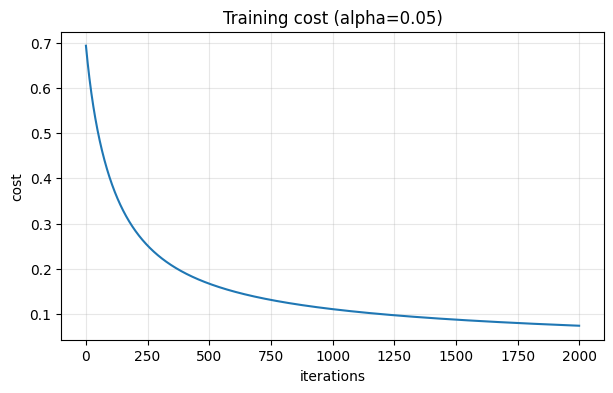

In [10]:
fig = plt.figure(figsize=(7, 4))
plt.plot(costs)
plt.ylabel('cost')
plt.xlabel('iterations')
plt.title(f'Training cost (alpha={ALPHA})')
plt.grid(alpha=0.3)
plt.savefig('costs')
plt.show()

## 9. Evaluate on the test set

In [11]:
y_pred_test = predict(theta, X_test)
m = metrics(y_test, y_pred_test)
print(f"TEST  accuracy={m['acc']:.3f}  precision={m['prec']:.3f}  recall={m['rec']:.3f}  F1={m['f1']:.3f}")
print()
print("                 predicted spam   predicted ham")
print(f"actual spam      TP = {m['TP']:<10} FN = {m['FN']}")
print(f"actual ham       FP = {m['FP']:<10} TN = {m['TN']}")

TEST  accuracy=0.995  precision=1.000  recall=0.978  F1=0.989

                 predicted spam   predicted ham
actual spam      TP = 44         FN = 1
actual ham       FP = 0          TN = 147


## 10. Example predictions

In [ ]:
probs = sigmoid(np.dot(X_test.T, theta)).ravel()
y_true = y_test.ravel()
y_hat = y_pred_test.ravel()

print("Examples from the test set:\n")
shown = {0: 0, 1: 0}
for k in range(len(te)):
    lab = int(y_true[k])
    if shown[lab] < 4:
        shown[lab] += 1
        print(f"true={'spam' if lab else 'ham ':4}  pred={'spam' if y_hat[k] else 'ham ':4}  "
              f"p(spam)={probs[k]:.3f} | {texts[te[k]][:75]}")

print("\nMisclassified test messages:")
for k in np.where(y_hat != y_true)[0]:
    print(f"true={'spam' if y_true[k] else 'ham'}  p(spam)={probs[k]:.3f} | {texts[te[k]][:75]}")

In [ ]:
def classify(msg):
    x = np.zeros((len(vocab) + 1, 1)); x[0, 0] = 1
    for t in set(preprocess(msg)):
        r = col.get(t)
        if r:
            x[r, 0] = 1
    p = sigmoid(np.dot(x.T, theta))[0, 0]
    return p, ("spam" if p >= 0.5 else "ham")

for msg in ["WINNER!! Claim your £1000 prize now, call 09061234567",
            "Hey, are we still meeting for lunch tomorrow?",
            "Free entry to win a Nokia, txt WIN to 80082 now",
            "Can you send me the notes from class today?"]:
    p, c = classify(msg)
    print(f"{c:4} (p={p:.3f}) | {msg}")

## 11. What did the model learn?
Largest positive weights push toward spam, most negative toward ham.

In [ ]:
order = np.argsort(theta[1:, 0])
print("Most spam-like words:", [vocab[i] for i in order[::-1][:10]])
print("Most ham-like words: ", [vocab[i] for i in order[:10]])

## Notes

- **Duplicates removed** before splitting to avoid leakage between train and test.
- **Class imbalance (~23% spam):** accuracy alone can mislead, so precision, recall and F1 are reported. Recall is the share of spam caught (TP / (TP + FN)); precision is the share of flagged messages that really are spam (TP / (TP + FP)).
- **Vocabulary built from training data only**, and α chosen on the validation set, so the test score is an honest estimate.
- **Small test set:** one message is about half a percentage point, so don't over-read differences between runs.